<a href="https://colab.research.google.com/github/sneha-g17/DSA-PROJECT/blob/main/EMOTION_DETECTOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Setup and Installation

In [ ]:
# Run this first in Colab
!pip install transformers datasets torch matplotlib seaborn bertviz

# Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.4/139.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.7/85.7 kB 3.3 MB/s eta 0:00:00


Step 2: Load Dataset from Hugging Face

In [ ]:
# Load the emotion dataset from dair-ai (similar to praveengovi's datasets)
dataset = load_dataset("dair-ai/emotion")

print("Dataset structure:")
print(dataset)
print("\nSample data:")
print(dataset['train'][0])

# The dataset has 'text' and 'label' columns
# Labels: 0-sadness, 1-joy, 2-love, 3-anger, 4-fear, 5-surprise

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

split/train-00000-of-00001.parquet:   0%|          | 0.00/1.03M [00:00<?, ?B/s]

split/validation-00000-of-00001.parquet:   0%|          | 0.00/127k [00:00<?, ?B/s]

split/test-00000-of-00001.parquet:   0%|          | 0.00/129k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Sample data:
{'text': 'i didnt feel humiliated', 'label': 0}


Step 3: Tokenization

In [ ]:
# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

# Tokenization function
def tokenize_data(examples):
    return tokenizer(
        examples['text'],
        padding='max_length',
        truncation=True,
        max_length=128,
        return_tensors='pt'
    )

# Example: See how tokenization works
sample_text = "I am so happy today!"
tokens = tokenizer(sample_text, return_tensors='pt')
print(f"\nOriginal text: {sample_text}")
print(f"Token IDs: {tokens['input_ids']}")
print(f"Tokens: {tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


Original text: I am so happy today!
Token IDs: tensor([[ 101, 1045, 2572, 2061, 3407, 2651,  999,  102]])
Tokens: ['[CLS]', 'i', 'am', 'so', 'happy', 'today', '!', '[SEP]']


Step 4: Build Custom Transformer Model

In [ ]:
class PositionalEncoding(nn.Module):
    """Adds positional information to embeddings"""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class MultiHeadSelfAttention(nn.Module):
    """Multi-head self-attention mechanism"""
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        batch_size = x.size(0)

        # Linear projections
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        # Split into multiple heads
        Q = Q.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.d_k)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        attention_weights = F.softmax(scores, dim=-1)
        attention_output = torch.matmul(attention_weights, V)

        # Concatenate heads
        attention_output = attention_output.transpose(1, 2).contiguous()
        attention_output = attention_output.view(batch_size, -1, self.d_model)

        output = self.W_o(attention_output)

        return output, attention_weights

class FeedForward(nn.Module):
    """Feed-forward network"""
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

class TransformerBlock(nn.Module):
    """Single transformer encoder block"""
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Multi-head attention with residual connection and normalization
        attn_output, attn_weights = self.attention(x, mask)
        x = self.norm1(x + self.dropout(attn_output))

        # Feed-forward with residual connection and normalization
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_output))

        return x, attn_weights

class EmotionDetector(nn.Module):
    """Complete emotion detection model"""
    def __init__(self, vocab_size, d_model=256, num_heads=8, num_layers=4,
                 num_classes=6, max_len=128, dropout=0.1):
        super().__init__()

        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, d_model)

        # Positional encoding
        self.pos_encoding = PositionalEncoding(d_model, max_len)

        # Transformer blocks
        self.transformer_blocks = nn.ModuleList([
            TransformerBlock(d_model, num_heads, d_model * 4, dropout)
            for _ in range(num_layers)
        ])

        # Classification head
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, num_classes)

        self.d_model = d_model

    def forward(self, x, mask=None):
        # Store attention weights for visualization
        attention_weights = []

        # Embedding
        x = self.embedding(x) * np.sqrt(self.d_model)

        # Positional encoding
        x = self.pos_encoding(x)
        x = self.dropout(x)

        # Pass through transformer blocks
        for transformer in self.transformer_blocks:
            x, attn = transformer(x, mask)
            attention_weights.append(attn)

        # Global average pooling
        x = x.mean(dim=1)

        # Classification
        output = self.fc(x)

        return output, attention_weights

Step 5: Prepare Data

In [ ]:
# Convert dataset to PyTorch format
def prepare_data(dataset_split):
    texts = list(dataset_split['text'])   # ✅ convert to list
    labels = list(dataset_split['label']) # ✅ convert to list

    encodings = tokenizer(
        texts,
        padding='max_length',
        truncation=True,
        max_length=128,
        return_tensors='pt'
    )

    return encodings['input_ids'], torch.tensor(labels)

# Prepare train and validation data
train_inputs, train_labels = prepare_data(dataset['train'])
val_inputs, val_labels = prepare_data(dataset['validation'])

# Create DataLoaders
train_dataset = torch.utils.data.TensorDataset(train_inputs, train_labels)
val_dataset = torch.utils.data.TensorDataset(val_inputs, val_labels)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")


Training samples: 16000
Validation samples: 2000


Step 6: Training

Training samples: 16000
Validation samples: 2000

Epoch 1/5


Training: 100%|██████████| 500/500 [30:20<00:00,  3.64s/it]


Train Loss: 1.4780, Train Acc: 41.08%
Val Loss: 1.2102, Val Acc: 56.60%

Epoch 2/5


Training: 100%|██████████| 500/500 [30:01<00:00,  3.60s/it]


Train Loss: 0.8595, Train Acc: 68.88%
Val Loss: 0.5659, Val Acc: 79.50%

Epoch 3/5


...

Train Loss: 0.4886, Train Acc: 82.52%
Val Loss: 0.4299, Val Acc: 85.35%

Epoch 4/5


Training: 100%|██████████| 500/500 [30:08<00:00,  3.62s/it]


Train Loss: 0.3655, Train Acc: 86.80%
Val Loss: 0.3838, Val Acc: 86.30%

Epoch 5/5


Training: 100%|██████████| 500/500 [30:24<00:00,  3.65s/it]


Train Loss: 0.2949, Train Acc: 89.09%
Val Loss: 0.3883, Val Acc: 85.95%


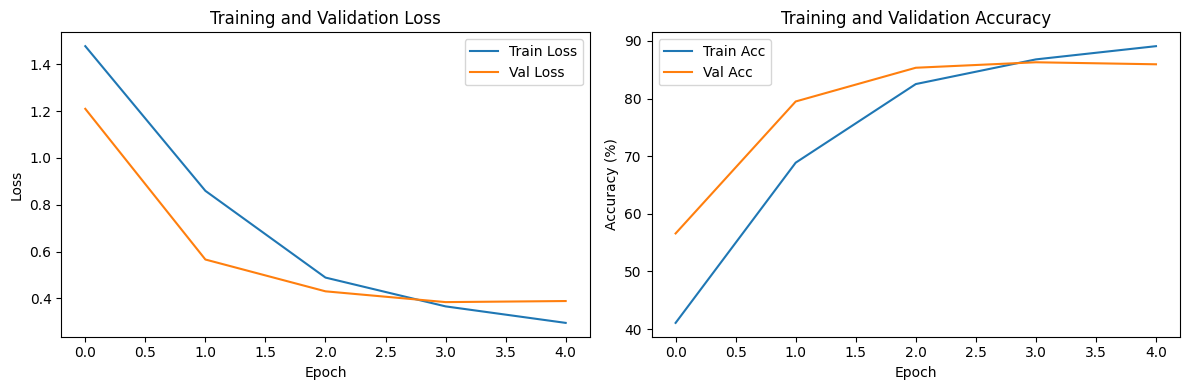

In [12]:
class PositionalEncoding(nn.Module):
    """Adds positional information to embeddings"""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class MultiHeadSelfAttention(nn.Module):
    """Multi-head self-attention mechanism"""
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        batch_size = x.size(0)

        # Linear projections
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        # Split into multiple heads
        Q = Q.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        # Scaled dot-product attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.d_k)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        attention_weights = F.softmax(scores, dim=-1)
        attention_output = torch.matmul(attention_weights, V)

        # Concatenate heads
        attention_output = attention_output.transpose(1, 2).contiguous()
        attention_output = attention_output.view(batch_size, -1, self.d_model)

        output = self.W_o(attention_output)

        return output, attention_weights

class FeedForward(nn.Module):
    """Feed-forward network"""
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

class TransformerBlock(nn.Module):
    """Single transformer encoder block"""
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Multi-head attention with residual connection and normalization
        attn_output, attn_weights = self.attention(x, mask)
        x = self.norm1(x + self.dropout(attn_output))

        # Feed-forward with residual connection and normalization
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_output))

        return x, attn_weights

class EmotionDetector(nn.Module):
    """Complete emotion detection model"""
    def __init__(self, vocab_size, d_model=256, num_heads=8, num_layers=4,
                 num_classes=6, max_len=128, dropout=0.1):
        super().__init__()

        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, d_model)

        # Positional encoding
        self.pos_encoding = PositionalEncoding(d_model, max_len)

        # Transformer blocks
        self.transformer_blocks = nn.ModuleList([
            TransformerBlock(d_model, num_heads, d_model * 4, dropout)
            for _ in range(num_layers)
        ])

        # Classification head
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, num_classes)

        self.d_model = d_model

    def forward(self, x, mask=None):
        # Store attention weights for visualization
        attention_weights = []

        # Embedding
        x = self.embedding(x) * np.sqrt(self.d_model)

        # Positional encoding
        x = self.pos_encoding(x)
        x = self.dropout(x)

        # Pass through transformer blocks
        for transformer in self.transformer_blocks:
            x, attn = transformer(x, mask)
            attention_weights.append(attn)

        # Global average pooling
        x = x.mean(dim=1)

        # Classification
        output = self.fc(x)

        return output, attention_weights

# Initialize tokenizer (moved here for robustness)
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

# Load the emotion dataset from dair-ai
dataset = load_dataset("dair-ai/emotion")

# Define emotion names (added here for robustness)
emotion_names = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

# Convert dataset to PyTorch format
def prepare_data(dataset_split):
    texts = list(dataset_split['text'])   # ✅ convert to list
    labels = list(dataset_split['label']) # ✅ convert to list

    encodings = tokenizer(
        texts,
        padding='max_length',
        truncation=True,
        max_length=128,
        return_tensors='pt'
    )

    return encodings['input_ids'], torch.tensor(labels)

# Prepare train and validation data
train_inputs, train_labels = prepare_data(dataset['train'])
val_inputs, val_labels = prepare_data(dataset['validation'])

# Create DataLoaders
train_dataset = torch.utils.data.TensorDataset(train_inputs, train_labels)
val_dataset = torch.utils.data.TensorDataset(val_inputs, val_labels)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

# Initialize model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = EmotionDetector(
    vocab_size=tokenizer.vocab_size,
    d_model=256,
    num_heads=8,
    num_layers=4,
    num_classes=6
).to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

# Training function
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in tqdm(loader, desc="Training"):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs, _ = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return total_loss / len(loader), 100. * correct / total

# Validation function
def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs, _ = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return total_loss / len(loader), 100. * correct / total

# Train the model
num_epochs = 5
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")

    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Val Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax1.legend()

ax2.plot(train_accs, label='Train Acc')
ax2.plot(val_accs, label='Val Acc')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Training and Validation Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm

Step 7: Attention Visualization


Text: I am so happy and excited!


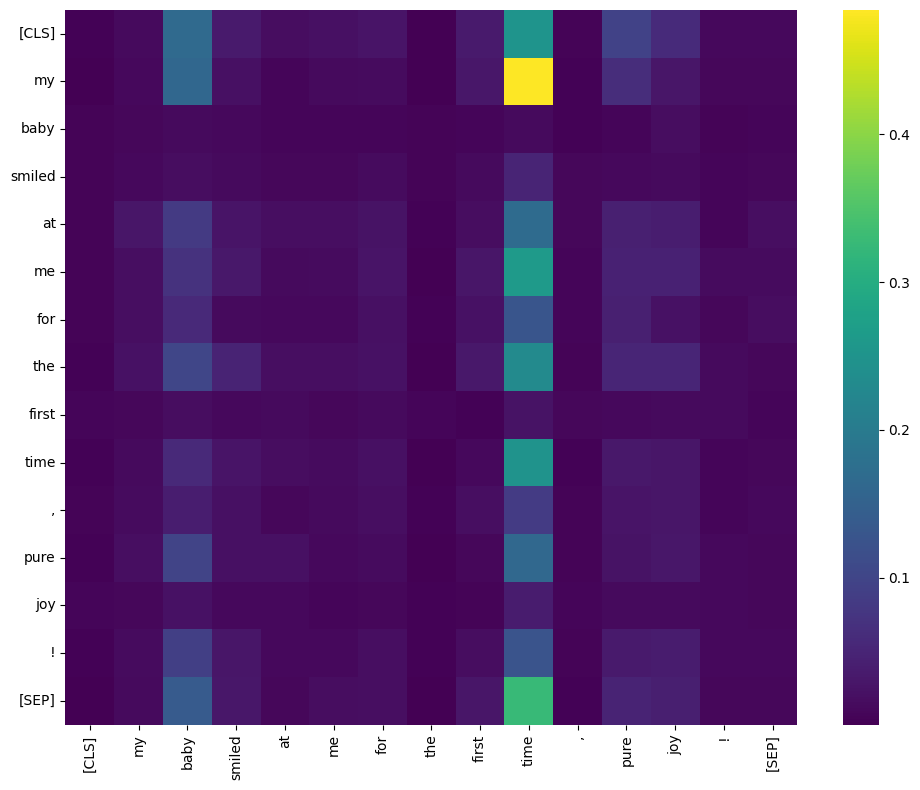

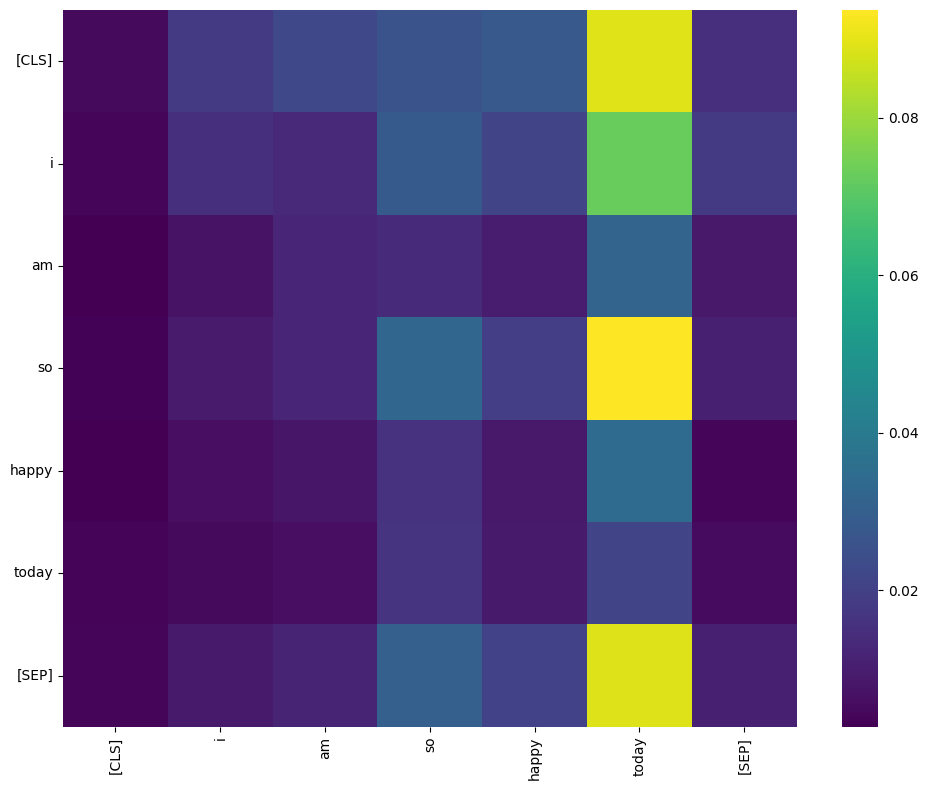

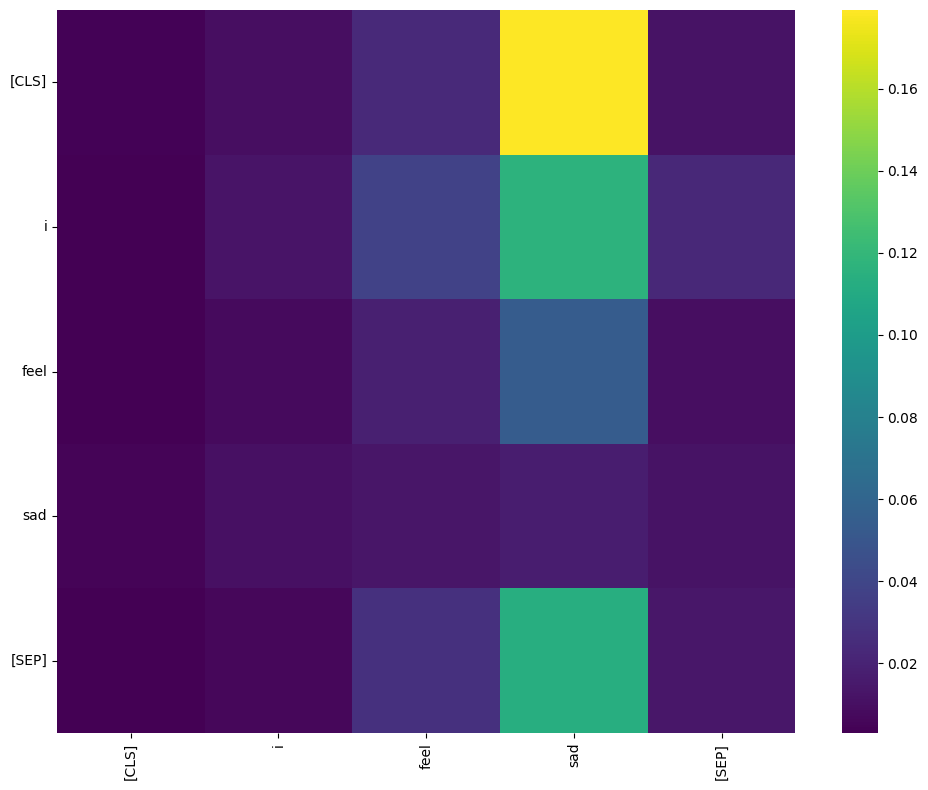

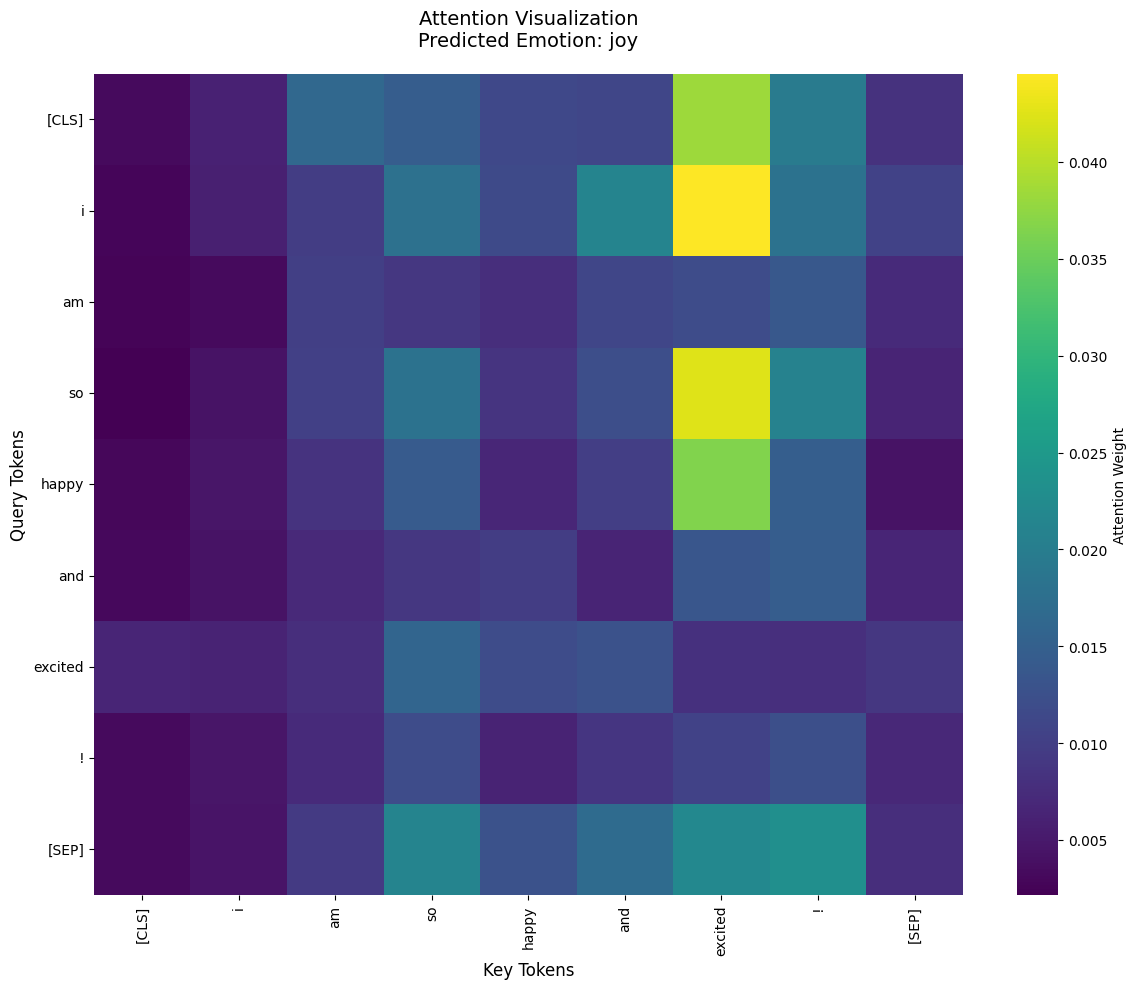

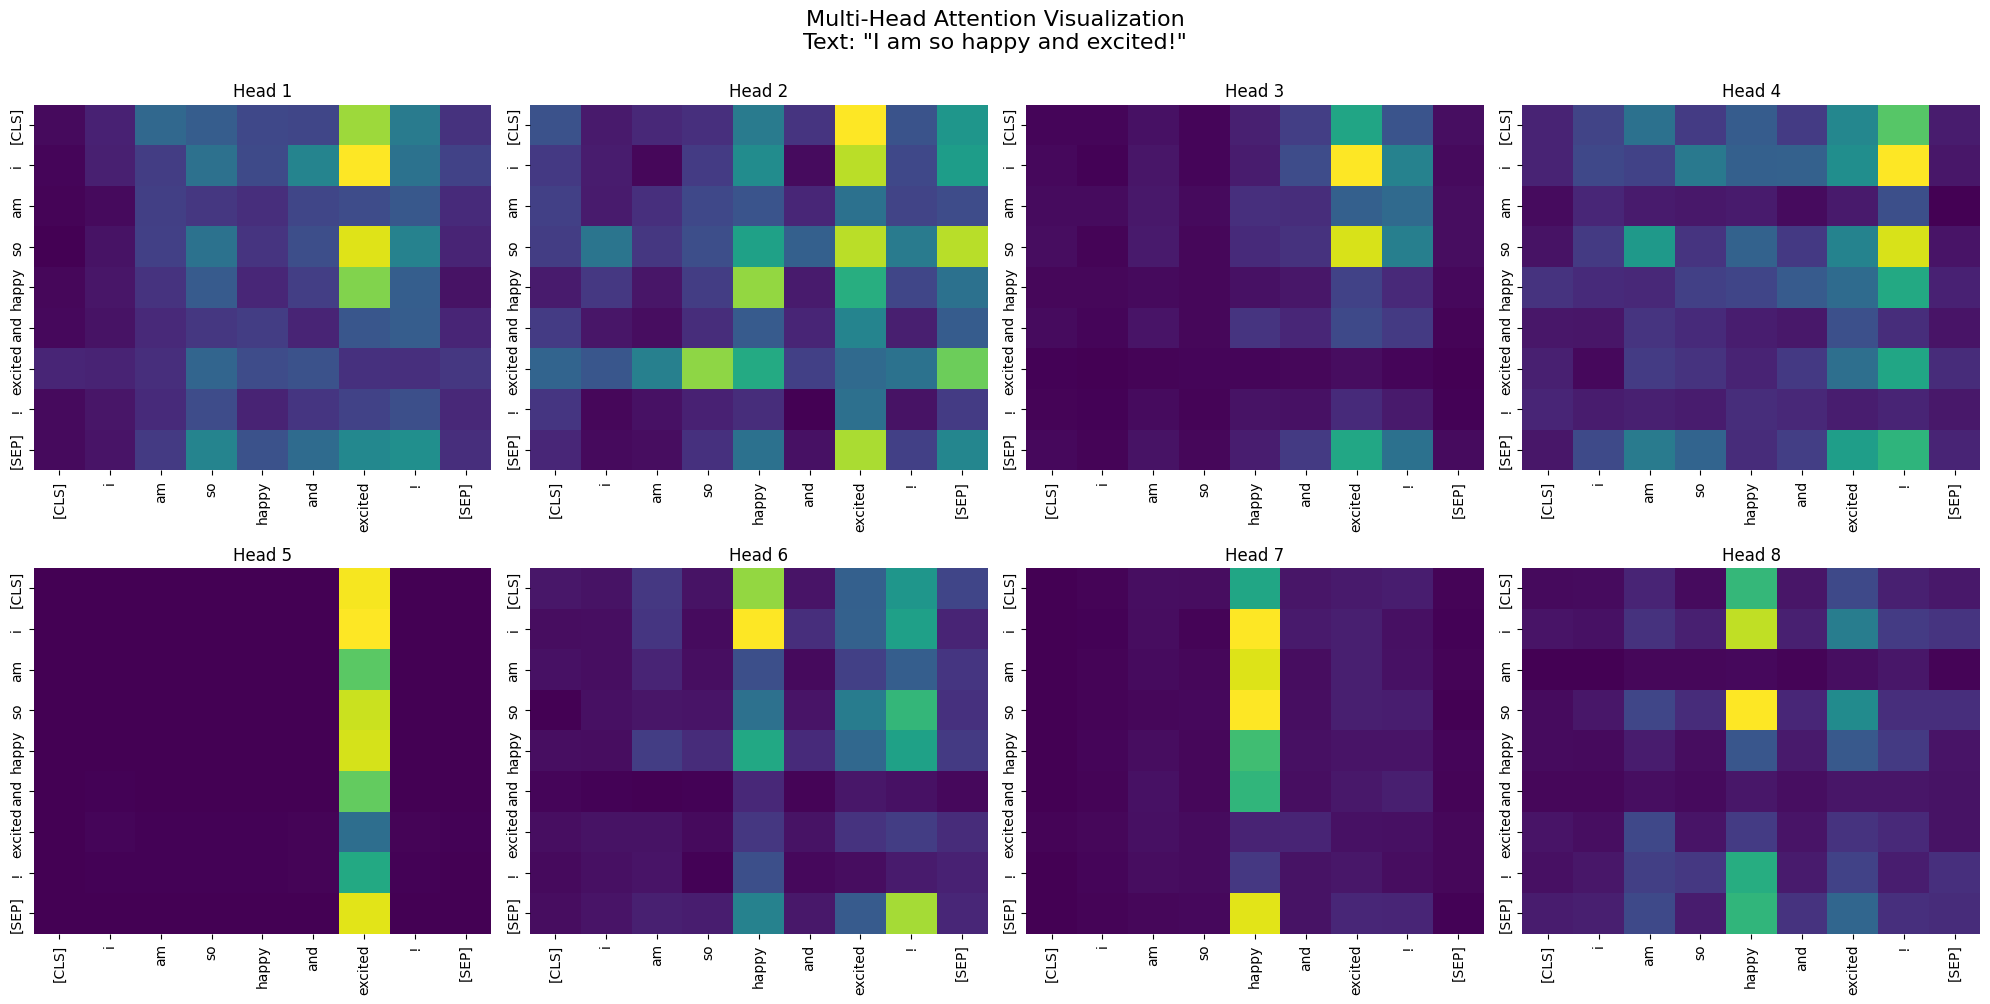

Predicted emotion: joy

Text: This makes me really angry


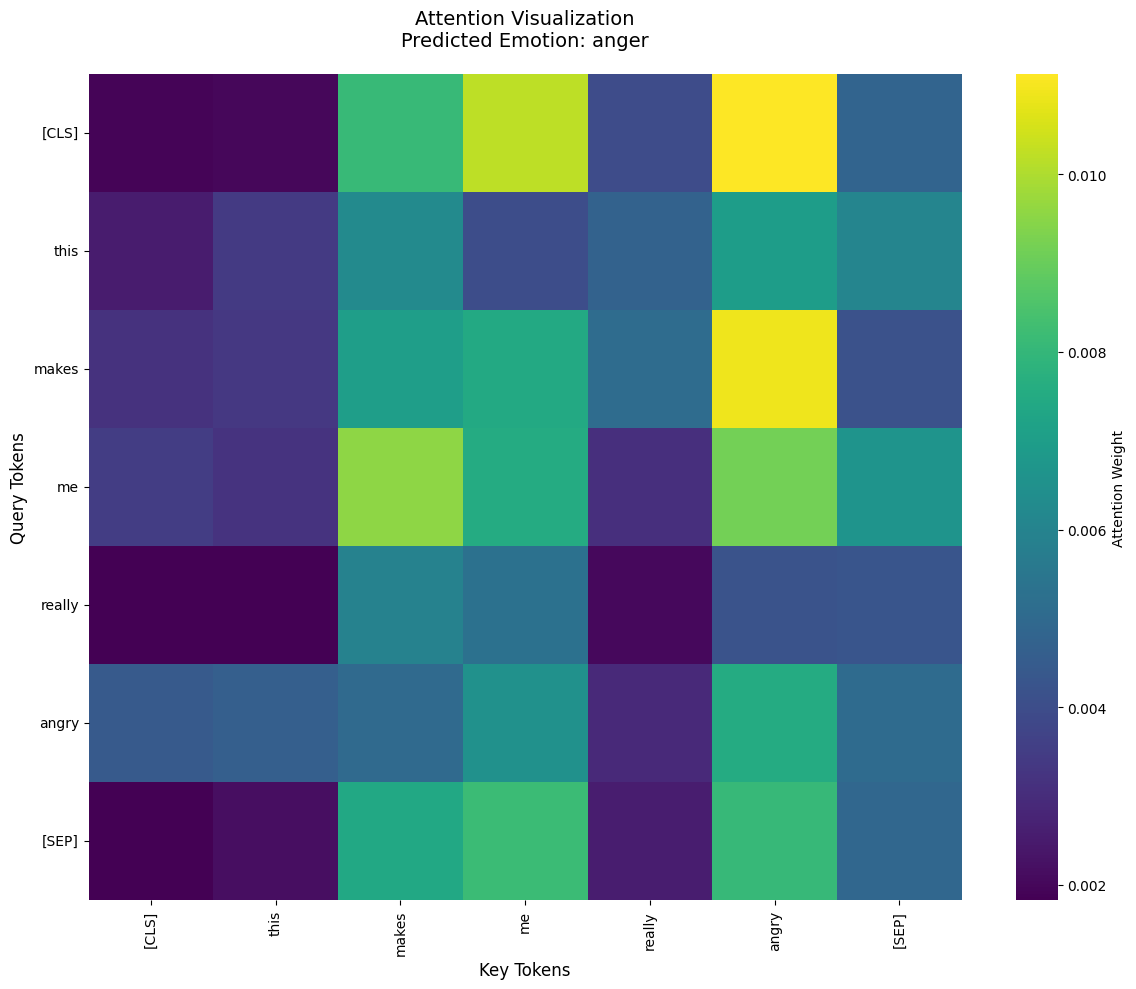

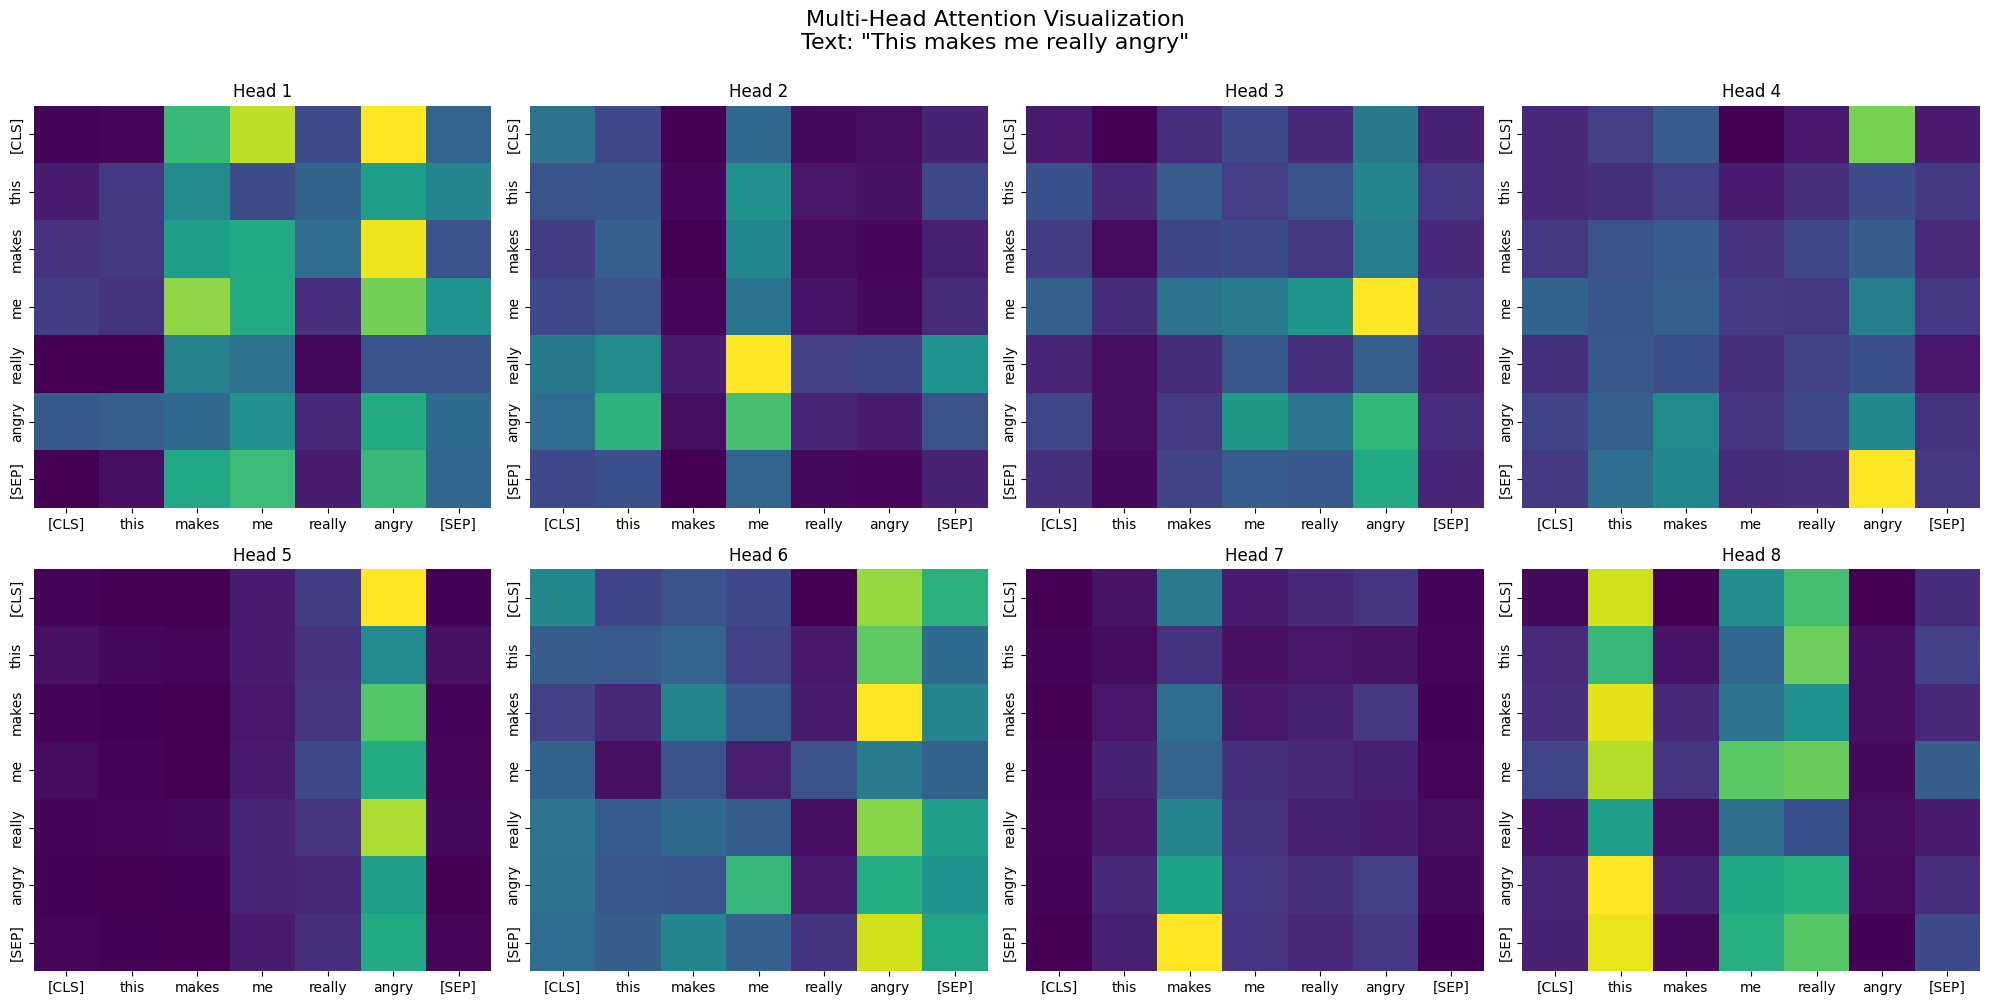

Predicted emotion: anger

Text: I love spending time with you


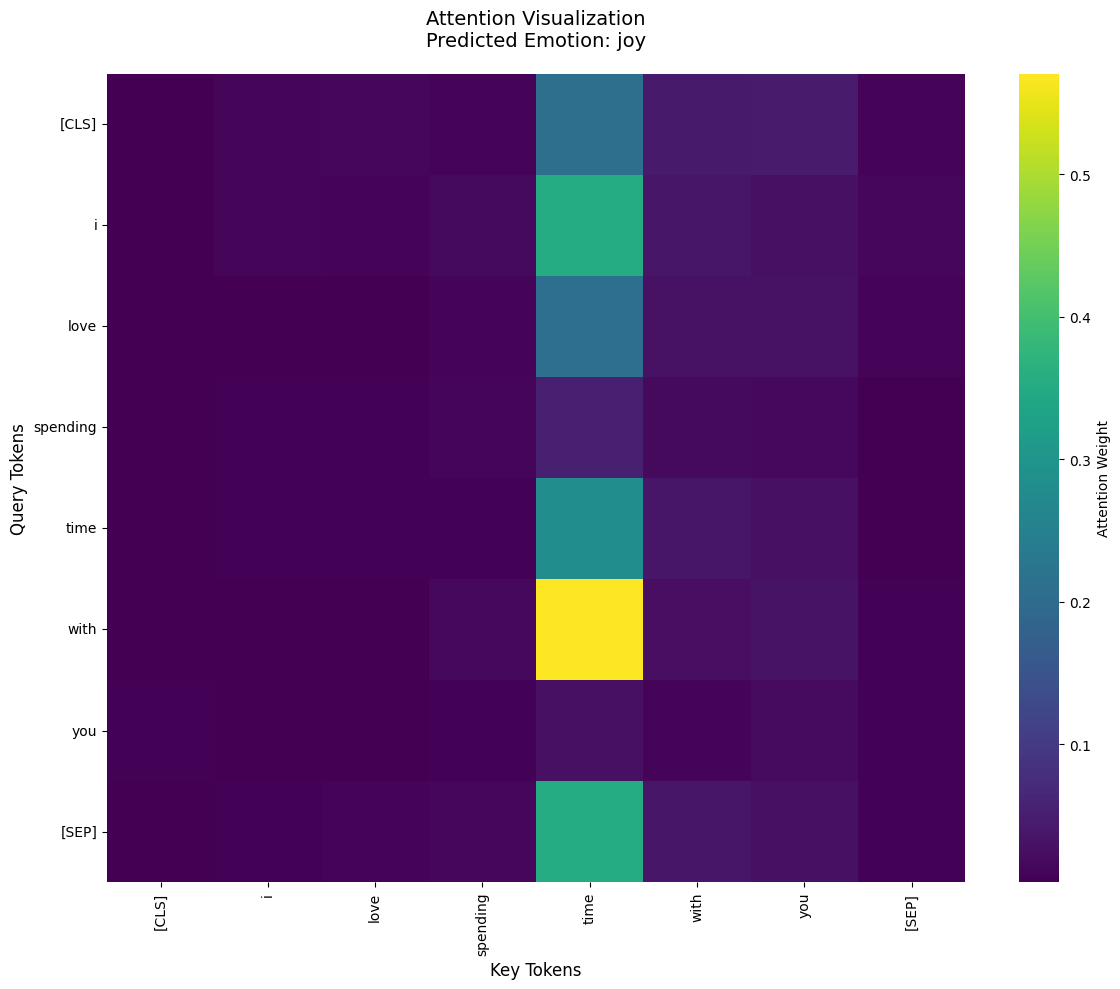

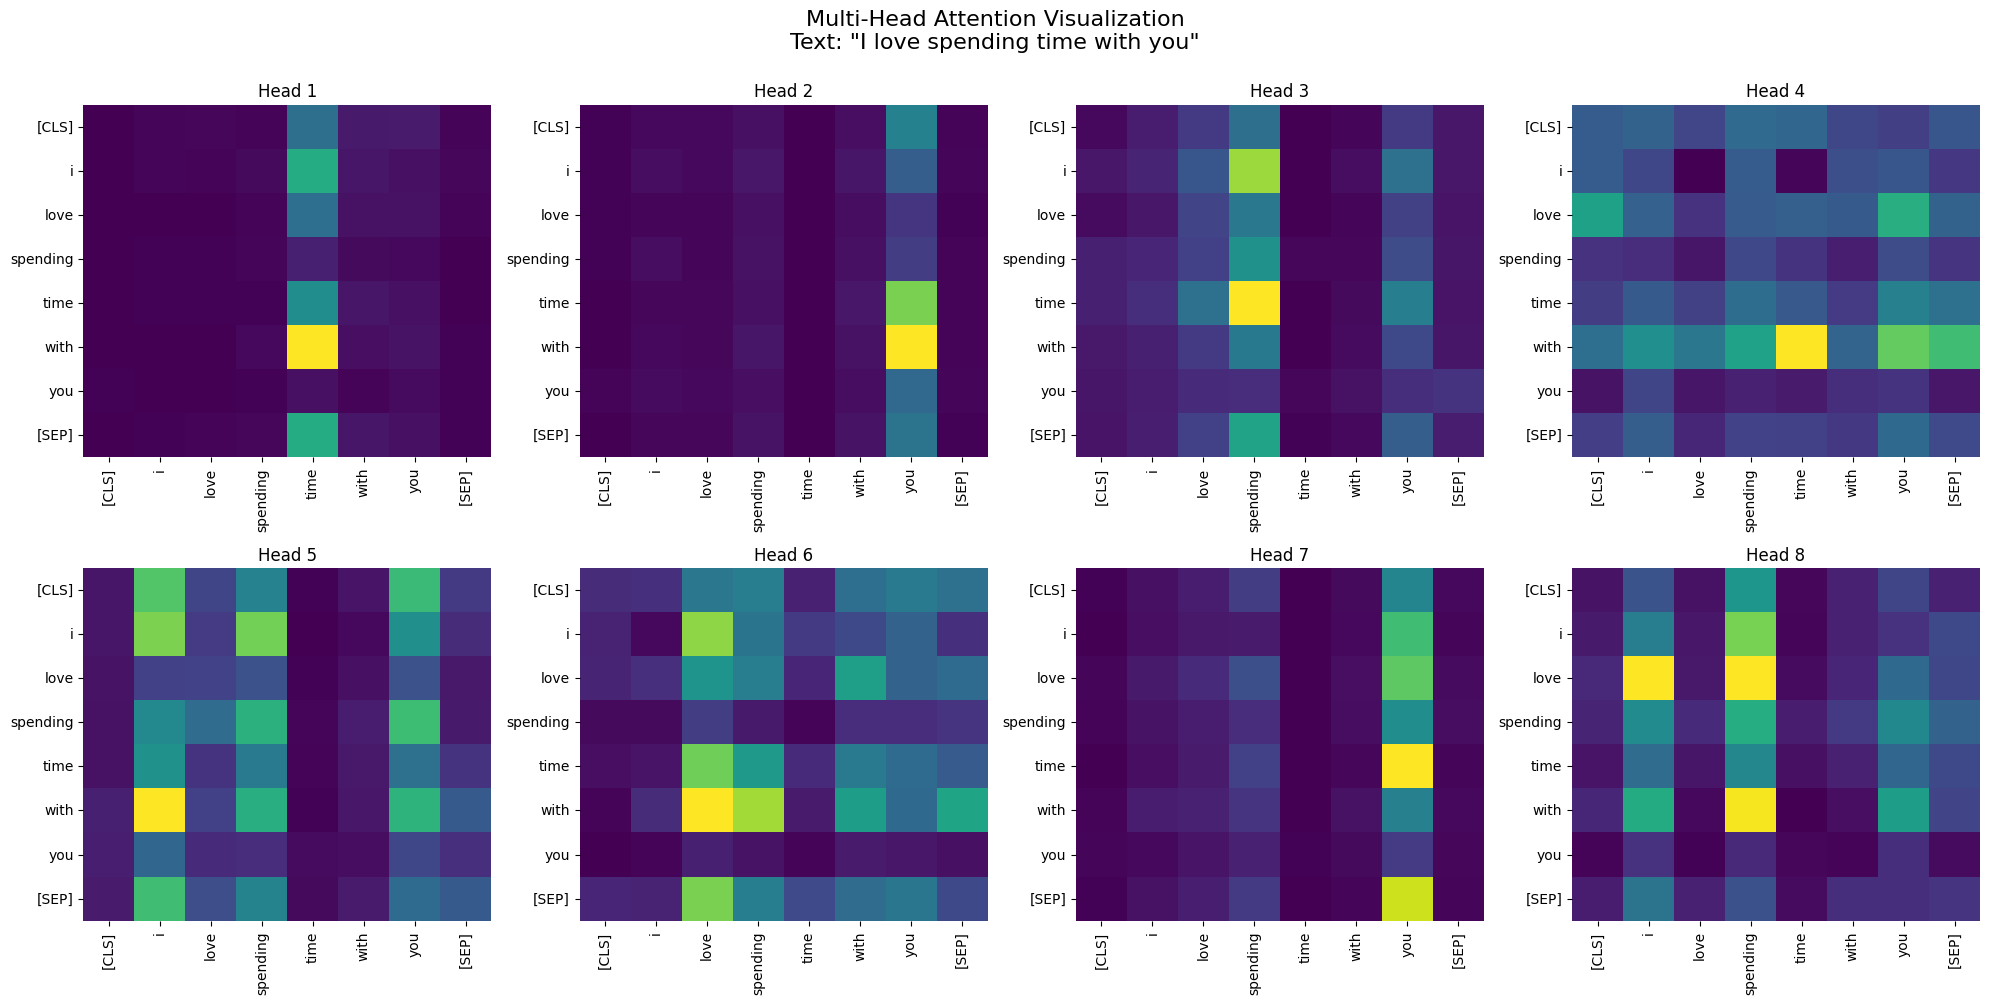

Predicted emotion: joy

Text: I'm feeling very sad today


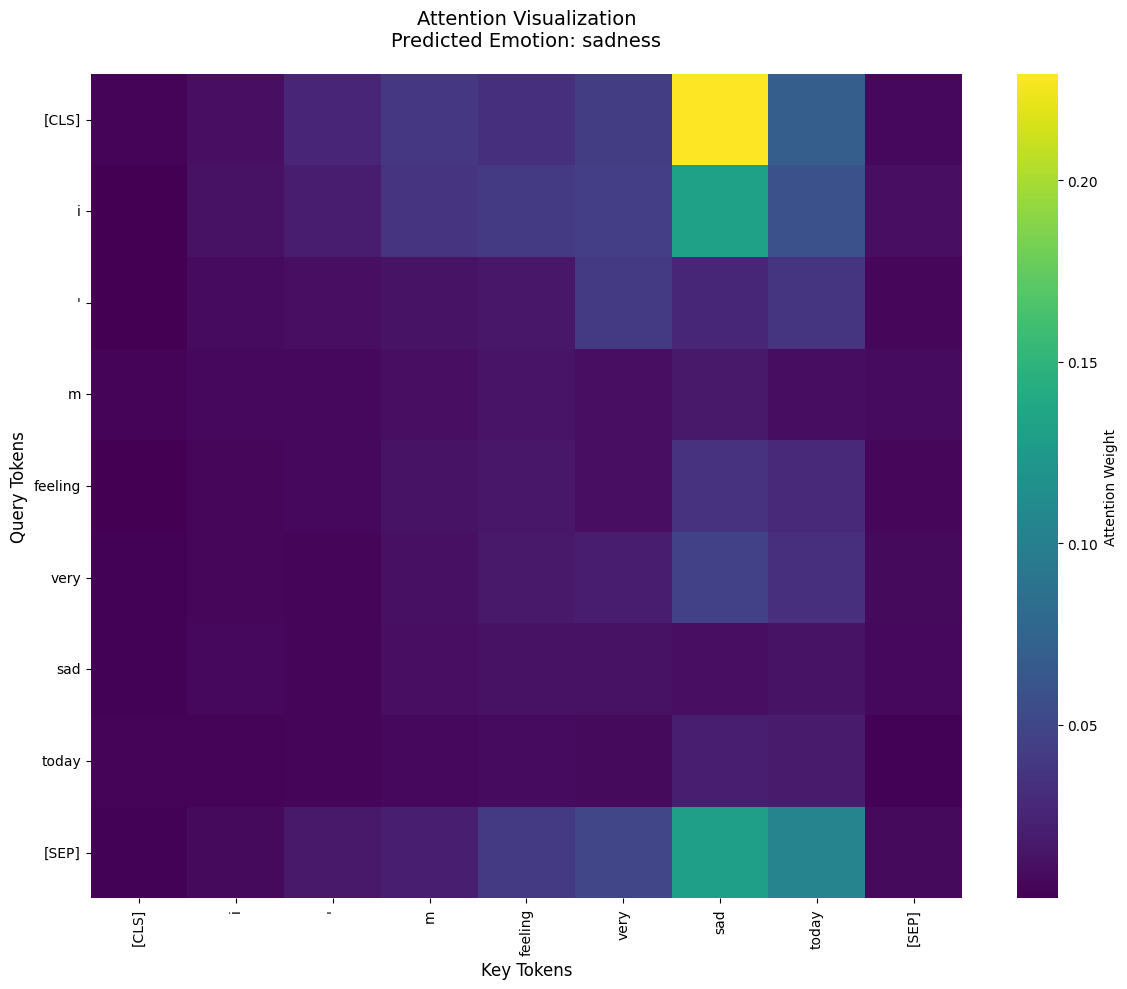

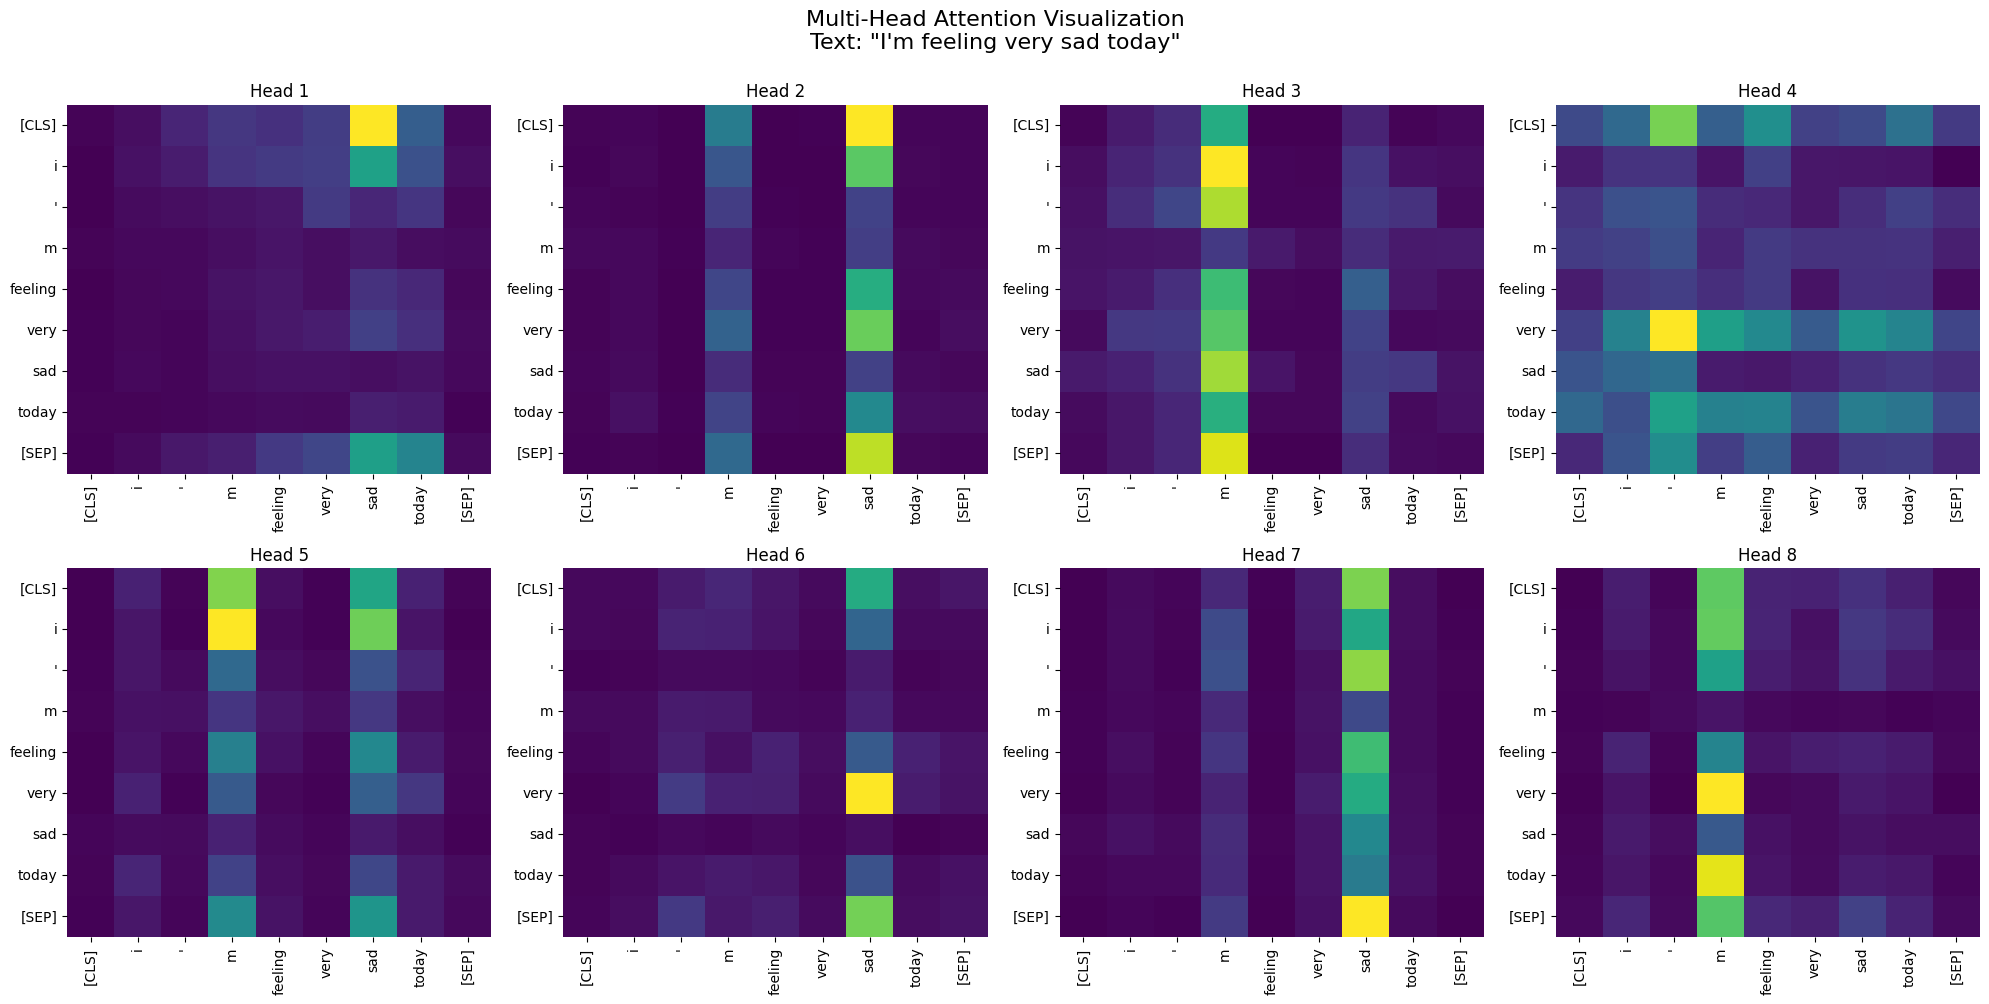

Predicted emotion: sadness

Text: That's really scary!


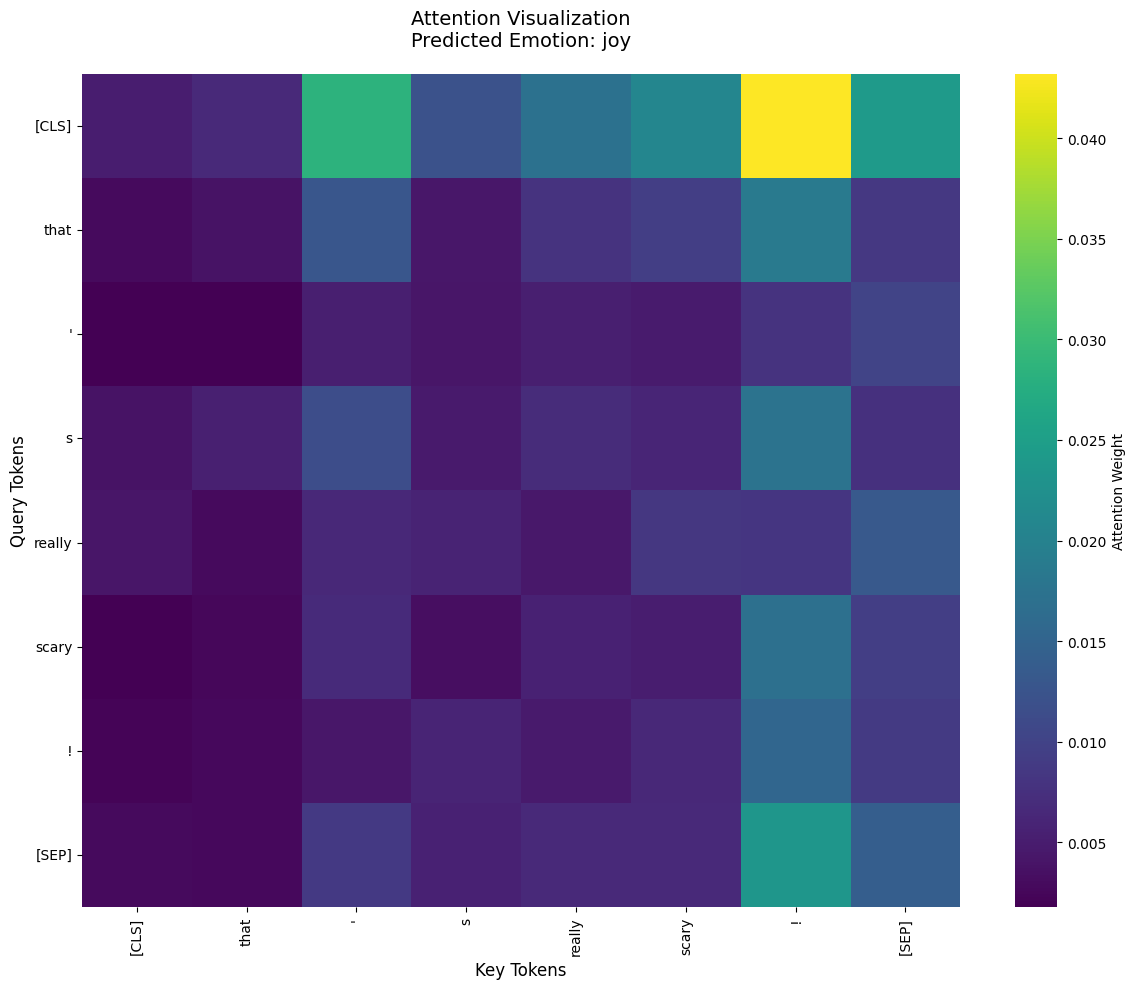

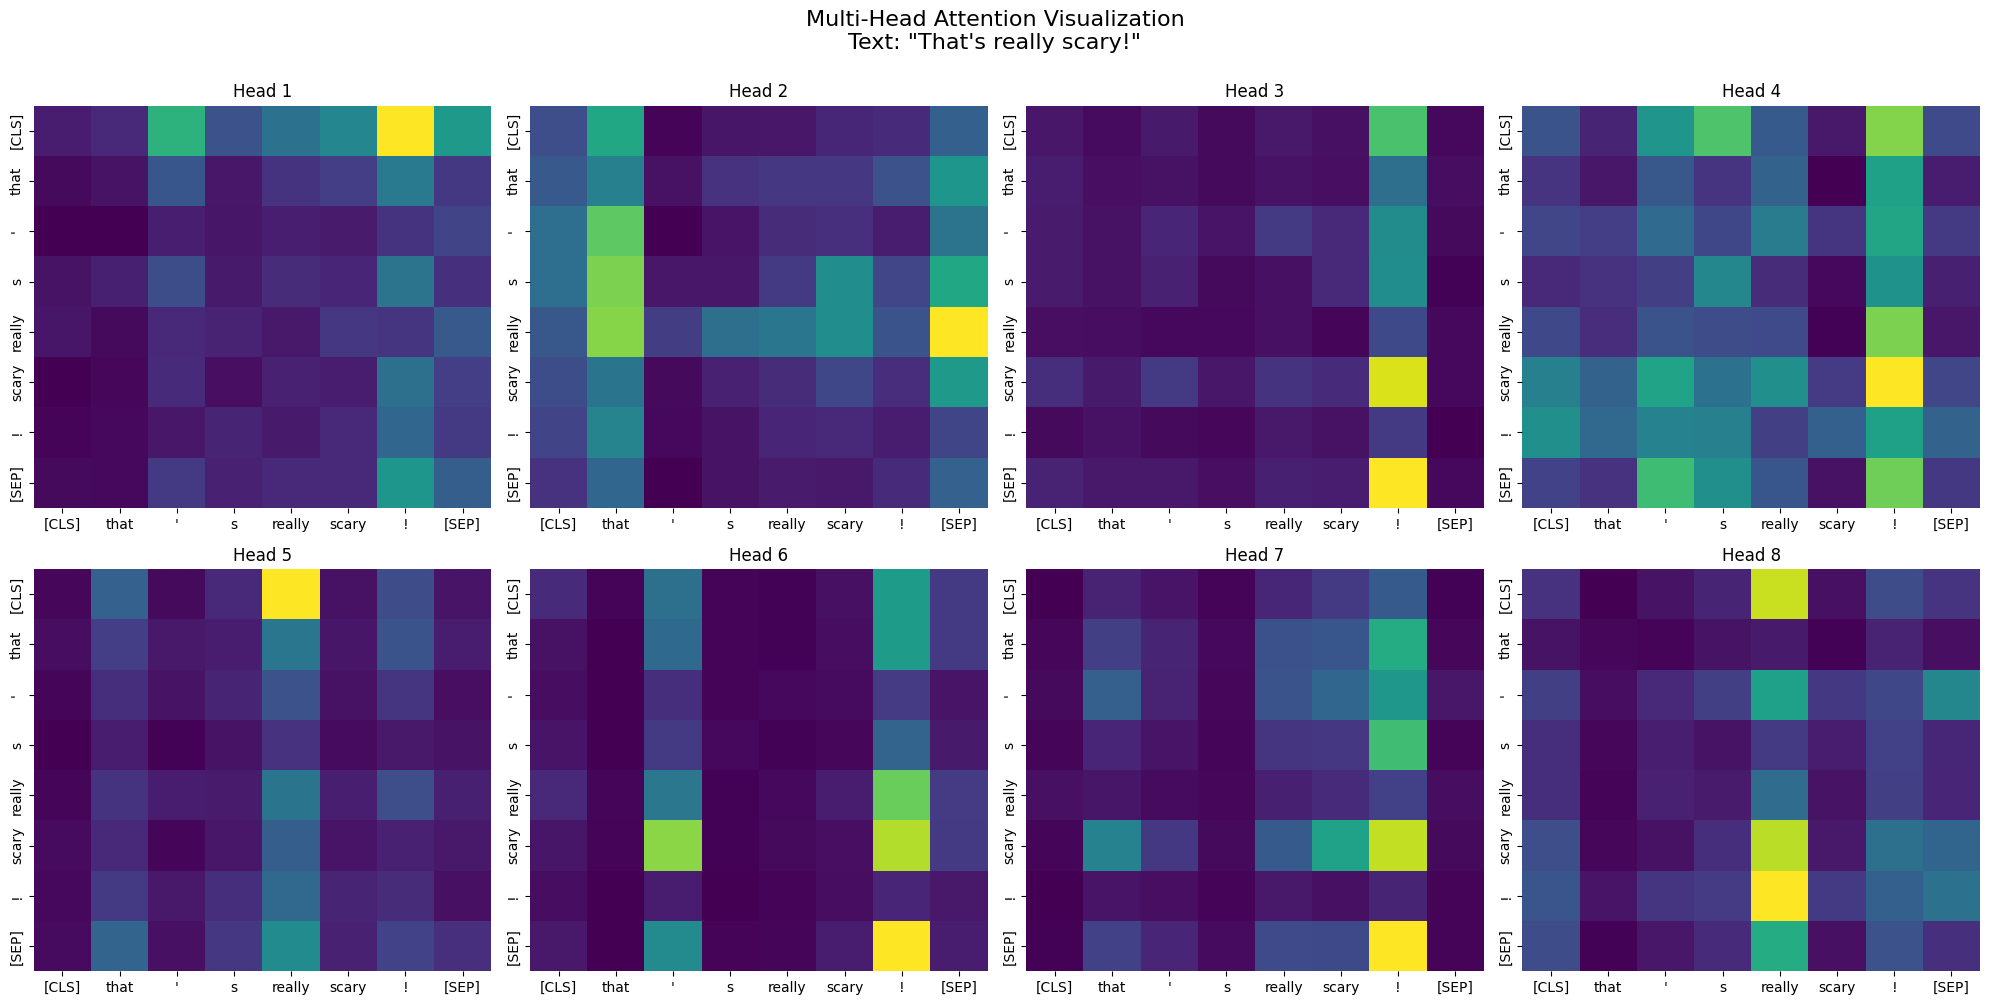

Predicted emotion: joy

Text: Wow, that's surprising!


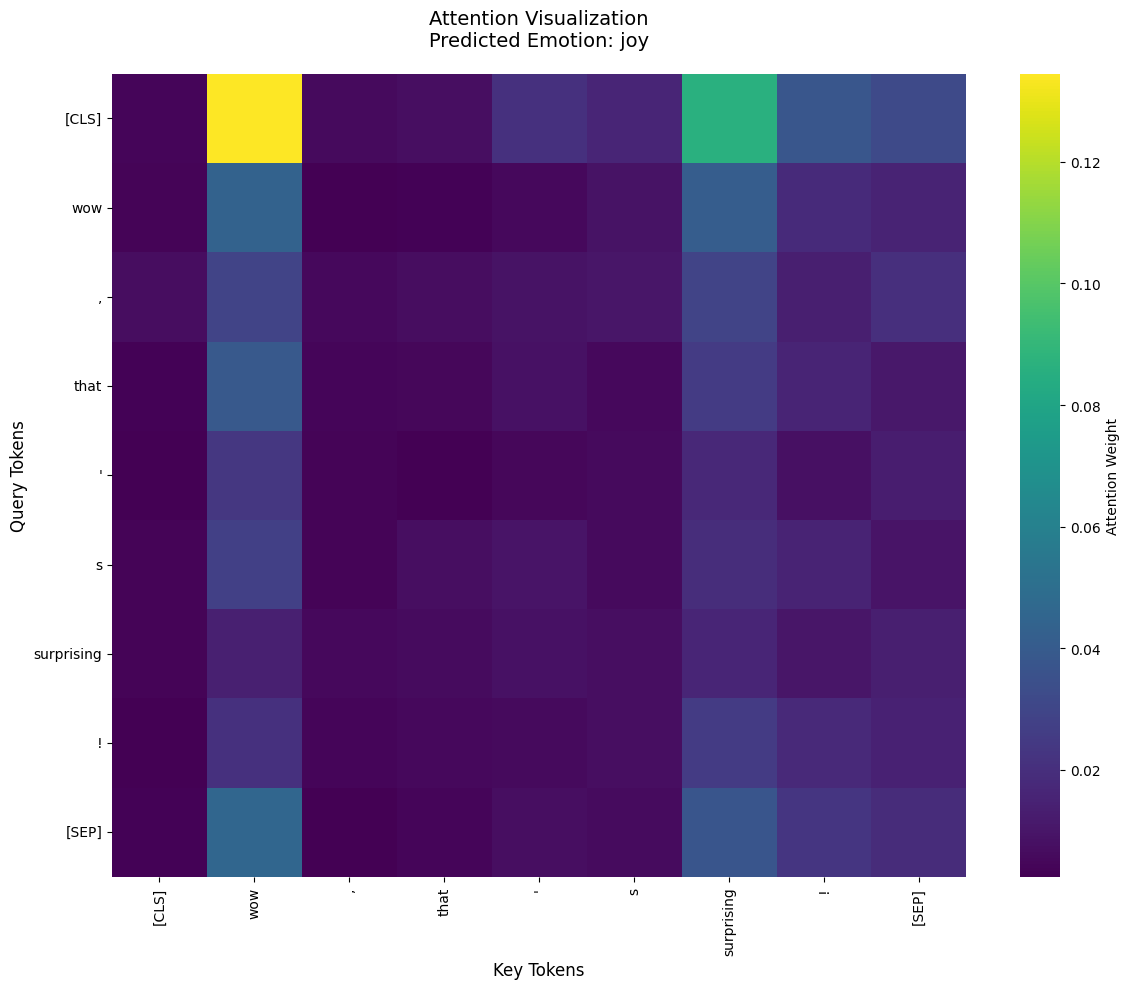

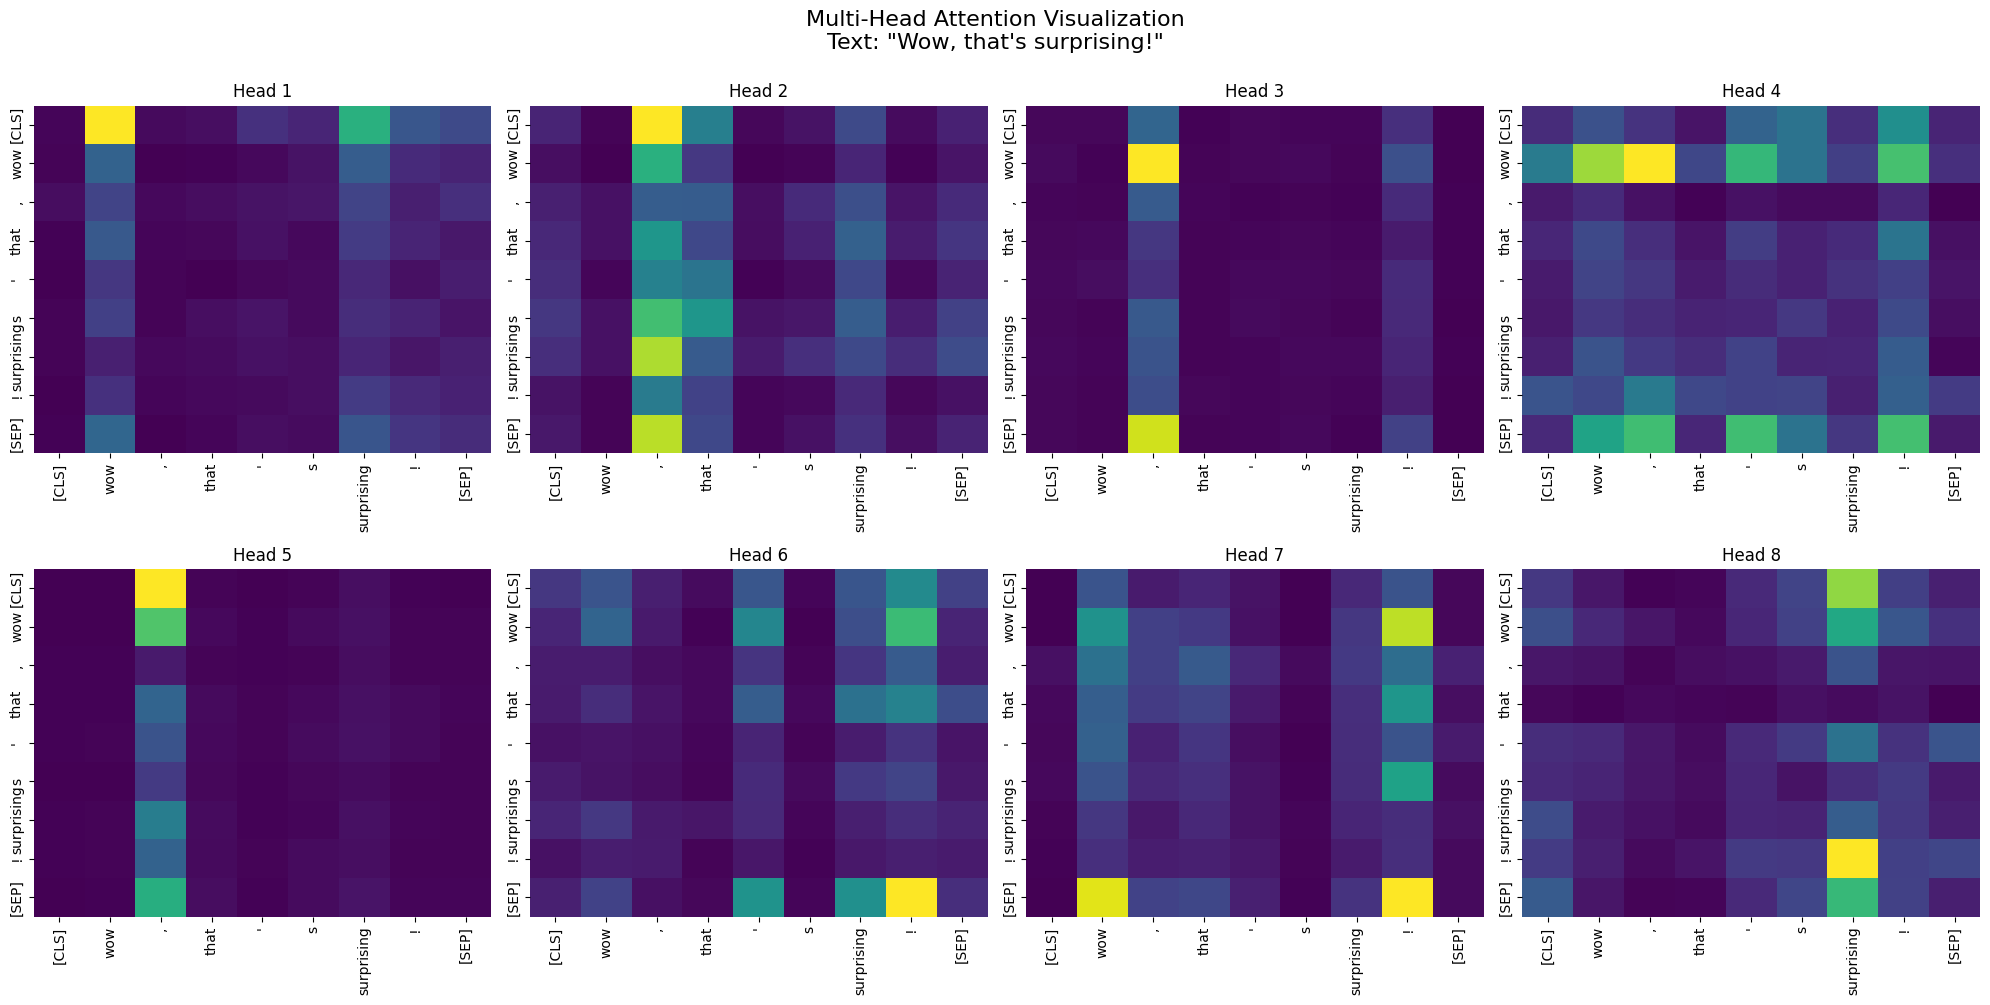

Predicted emotion: joy


In [21]:
emotion_names = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise"
}

def visualize_attention(model, text, tokenizer, device):
    """Visualize attention patterns for a given text"""
    model.eval()

    # Tokenize
    inputs = tokenizer(text, return_tensors='pt', padding='max_length',
                      truncation=True, max_length=128)
    input_ids = inputs['input_ids'].to(device)

    # Get predictions and attention weights
    with torch.no_grad():
        outputs, attention_weights = model(input_ids)
        prediction = torch.argmax(outputs, dim=1).item()

    # Get tokens
    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])

    # Find actual tokens (non-padding)
    actual_length = (input_ids[0] != tokenizer.pad_token_id).sum().item()
    tokens = tokens[:actual_length]

    # Visualize attention from last layer, first head
    attention = attention_weights[-1][0, 0, :actual_length, :actual_length].cpu().numpy()

    # Create visualization
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(attention, xticklabels=tokens, yticklabels=tokens,
                cmap='viridis', ax=ax, cbar_kws={'label': 'Attention Weight'})

    ax.set_title(f'Attention Visualization\nPredicted Emotion: {emotion_names[prediction]}',
                 fontsize=14, pad=20)
    ax.set_xlabel('Key Tokens', fontsize=12)
    ax.set_ylabel('Query Tokens', fontsize=12)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Visualize all heads
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for head in range(8):
        attention = attention_weights[-1][0, head, :actual_length, :actual_length].cpu().numpy()
        sns.heatmap(attention, ax=axes[head], cmap='viridis',
                   xticklabels=tokens, yticklabels=tokens, cbar=False)
        axes[head].set_title(f'Head {head+1}')
        axes[head].set_xlabel('')
        axes[head].set_ylabel('')

    plt.suptitle(f'Multi-Head Attention Visualization\nText: "{text}"',
                 fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()

    return prediction

# Test with sample texts
test_texts = [
    "I am so happy and excited!",
    "This makes me really angry",
    "I love spending time with you",
    "I'm feeling very sad today",
    "That's really scary!",
    "Wow, that's surprising!"
]

for text in test_texts:
    print(f"\n{'='*50}")
    print(f"Text: {text}")
    pred = visualize_attention(model, text, tokenizer, device)
    print(f"Predicted emotion: {emotion_names[pred]}")

Step 8: Component Visualization

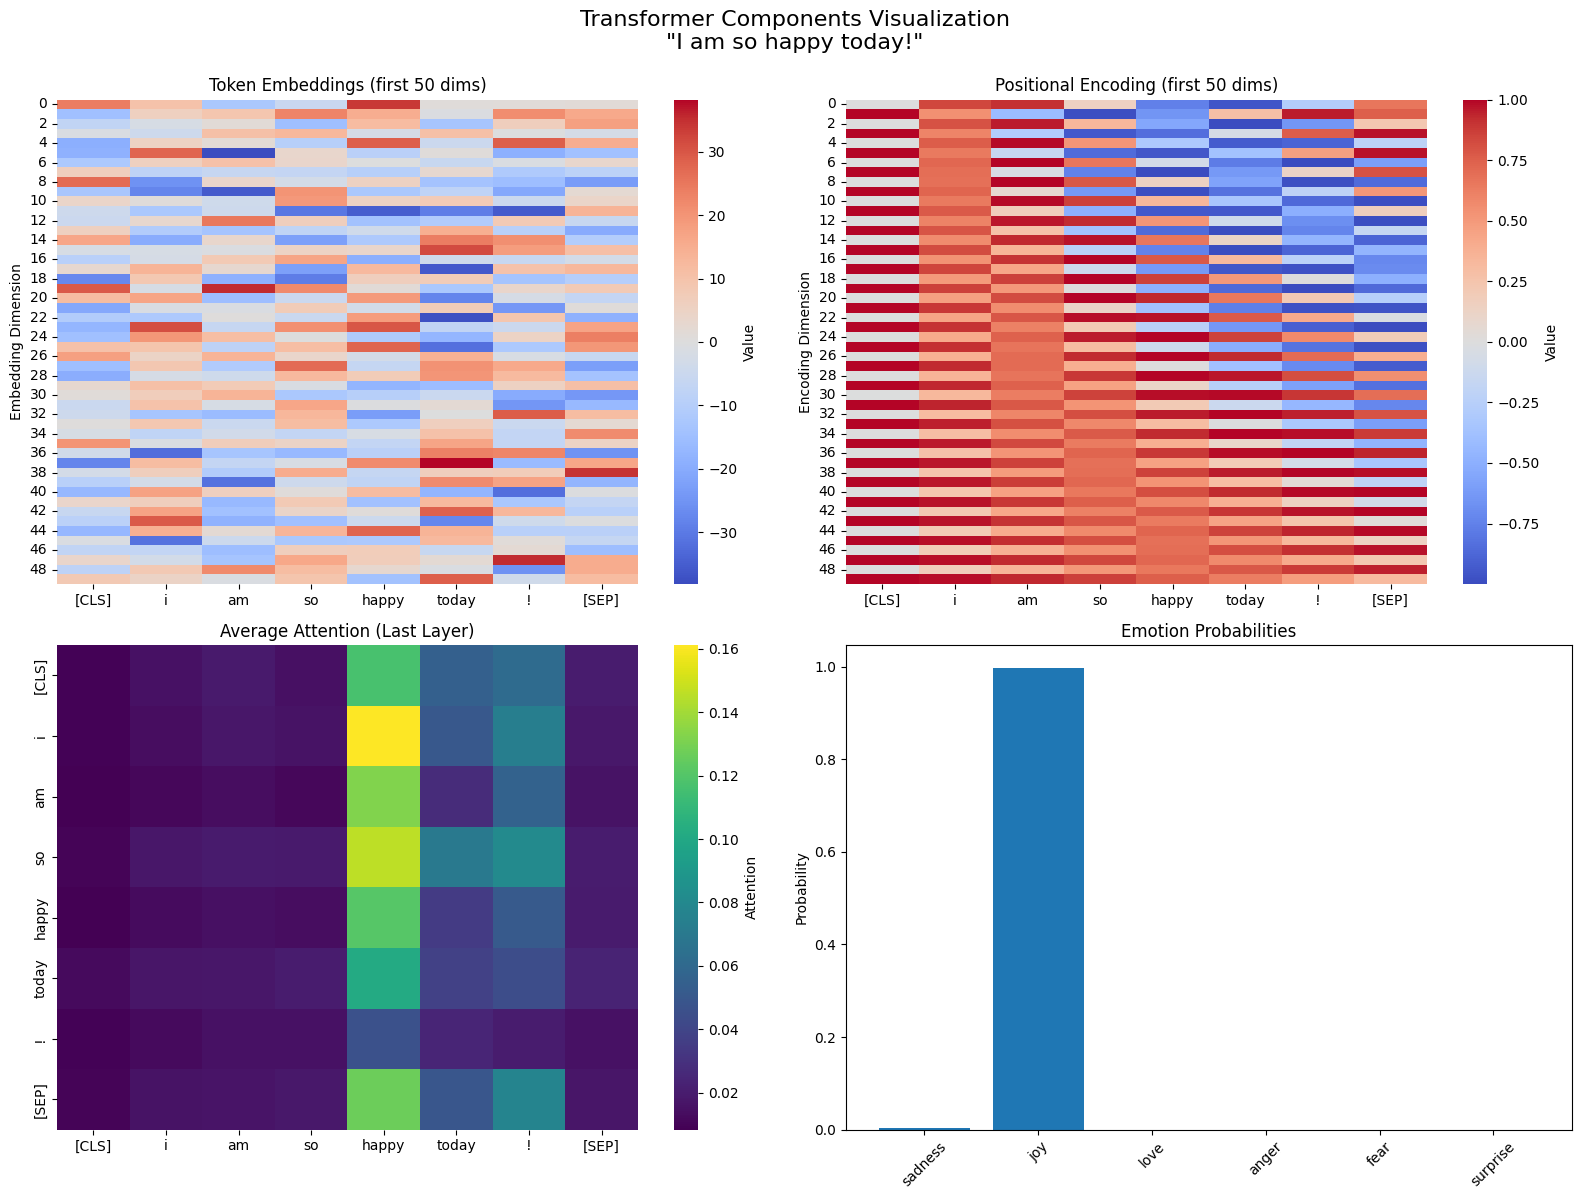

In [25]:
emotion_names = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise"
}

def visualize_components(model, text, tokenizer, device):
    """Visualize embeddings, positional encoding, and attention"""
    model.eval()

    # Tokenize
    inputs = tokenizer(text, return_tensors='pt', padding='max_length',
                      truncation=True, max_length=128)
    input_ids = inputs['input_ids'].to(device)

    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])
    actual_length = (input_ids[0] != tokenizer.pad_token_id).sum().item()
    tokens = tokens[:actual_length]

    with torch.no_grad():
        # Get embeddings
        embeddings = model.embedding(input_ids) * np.sqrt(model.d_model)

        # Get positional encoding
        pos_encoded = model.pos_encoding(embeddings)

        # Get final output
        outputs, attention_weights = model(input_ids)

    # Visualize
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # 1. Token Embeddings
    emb_viz = embeddings[0, :actual_length, :50].cpu().numpy()
    sns.heatmap(emb_viz.T, ax=axes[0, 0], cmap='coolwarm', center=0,
                xticklabels=tokens, cbar_kws={'label': 'Value'})
    axes[0, 0].set_title('Token Embeddings (first 50 dims)')
    axes[0, 0].set_ylabel('Embedding Dimension')

    # 2. Positional Encoding
    pos_viz = (pos_encoded - embeddings)[0, :actual_length, :50].cpu().numpy()
    sns.heatmap(pos_viz.T, ax=axes[0, 1], cmap='coolwarm', center=0,
                xticklabels=tokens, cbar_kws={'label': 'Value'})
    axes[0, 1].set_title('Positional Encoding (first 50 dims)')
    axes[0, 1].set_ylabel('Encoding Dimension')

    # 3. Attention Weights
    attn_viz = attention_weights[-1][0].mean(0)[:actual_length, :actual_length].cpu().numpy()
    sns.heatmap(attn_viz, ax=axes[1, 0], cmap='viridis',
                xticklabels=tokens, yticklabels=tokens,
                cbar_kws={'label': 'Attention'})
    axes[1, 0].set_title('Average Attention (Last Layer)')

       # 4. Prediction Probabilities
    probs = F.softmax(outputs[0], dim=0).cpu().numpy()

    # FIX: convert dict → list of labels
    labels = list(emotion_names.values())

    axes[1, 1].bar(labels, probs)
    axes[1, 1].set_title('Emotion Probabilities')
    axes[1, 1].set_ylabel('Probability')
    axes[1, 1].tick_params(axis='x', rotation=45)


    plt.suptitle(f'Transformer Components Visualization\n"{text}"',
                 fontsize=16, y=0.995)
    plt.tight_layout()
    plt.show()

# Test visualization
visualize_components(model, "I am so happy today!", tokenizer, device)

Enhancements

In [26]:
!pip install gradio

import gradio as gr

def predict_emotion(text):
    model.eval()
    inputs = tokenizer(text, return_tensors='pt', padding='max_length',
                      truncation=True, max_length=128).to(device)

    with torch.no_grad():
        outputs, attention_weights = model(inputs['input_ids'])
        probs = F.softmax(outputs[0], dim=0).cpu().numpy()

    # Create probability dictionary
    emotion_probs = {emotion_names[i]: float(probs[i]) for i in range(6)}

    # Create attention visualization
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    actual_length = (inputs['input_ids'][0] != tokenizer.pad_token_id).sum().item()
    tokens = tokens[:actual_length]
    attention = attention_weights[-1][0, 0, :actual_length, :actual_length].cpu().numpy()

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(attention, xticklabels=tokens, yticklabels=tokens,
                cmap='viridis', ax=ax)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()

    return emotion_probs, fig

# Create Gradio interface
demo = gr.Interface(
    fn=predict_emotion,
    inputs=gr.Textbox(lines=3, placeholder="Enter text to analyze emotion..."),
    outputs=[
        gr.Label(num_top_classes=6, label="Emotion Probabilities"),
        gr.Plot(label="Attention Visualization")
    ],
    title="🎭 Emotion Detector with Attention Visualization",
    description="Enter any text to detect emotions and visualize attention patterns",
    examples=[
        ["I am so happy and excited!"],
        ["This makes me really angry"],
        ["I love spending time with you"],
        ["I'm feeling very sad today"]
    ]
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3c60bcdc6172afe819.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [16]:
# Save trained model
torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'train_accs': train_accs,
    'val_accs': val_accs
}, 'emotion_detector_model.pth')

print("Model saved successfully!")

# Load model later
checkpoint = torch.load('emotion_detector_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])
print("Model loaded successfully!")

Model saved successfully!
Model loaded successfully!


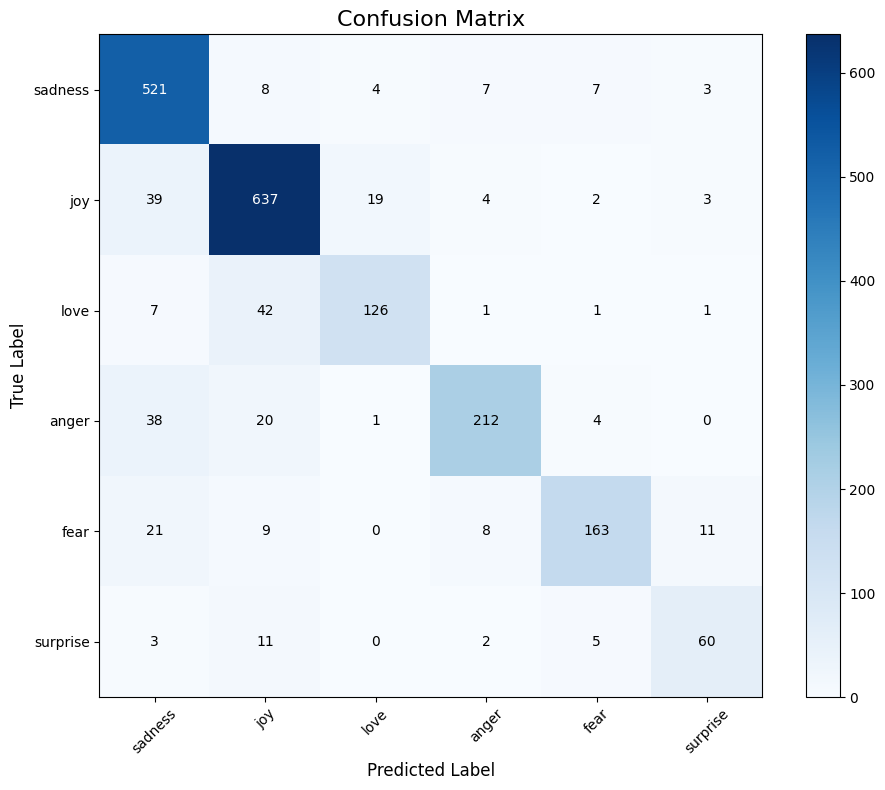


Classification Report:
              precision    recall  f1-score   support

     sadness       0.83      0.95      0.88       550
         joy       0.88      0.90      0.89       704
        love       0.84      0.71      0.77       178
       anger       0.91      0.77      0.83       275
        fear       0.90      0.77      0.83       212
    surprise       0.77      0.74      0.75        81

    accuracy                           0.86      2000
   macro avg       0.85      0.81      0.83      2000
weighted avg       0.86      0.86      0.86      2000



In [29]:
from sklearn.metrics import confusion_matrix, classification_report
import itertools

def plot_confusion_matrix(model, loader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs, _ = model(inputs)
            _, preds = outputs.max(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.title('Confusion Matrix', fontsize=16)
    plt.colorbar()

    # Convert dictionary to list
    label_names = list(emotion_names.values())

    tick_marks = np.arange(len(label_names))
    plt.xticks(tick_marks, label_names, rotation=45)
    plt.yticks(tick_marks, label_names)

    # Add text annotations
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    plt.show()

    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds,
                                target_names=label_names))


plot_confusion_matrix(model, val_loader, device)

In [30]:
def compare_attention_heads(model, text, tokenizer, device):
    """Compare what different attention heads focus on"""
    model.eval()

    inputs = tokenizer(text, return_tensors='pt', padding='max_length',
                      truncation=True, max_length=128).to(device)

    with torch.no_grad():
        outputs, attention_weights = model(inputs['input_ids'])

    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    actual_length = (inputs['input_ids'][0] != tokenizer.pad_token_id).sum().item()
    tokens = tokens[:actual_length]

    # Get attention from last layer
    last_layer_attention = attention_weights[-1][0]  # [num_heads, seq_len, seq_len]

    # For each head, find which token it focuses on most
    print(f"\nText: {text}\n")
    print("What each attention head focuses on:")
    print("-" * 50)

    for head_idx in range(last_layer_attention.shape[0]):
        # Average attention across all query positions
        avg_attention = last_layer_attention[head_idx].mean(0)[:actual_length].cpu().numpy()

        # Find top 3 tokens this head focuses on
        top_indices = avg_attention.argsort()[-3:][::-1]
        top_tokens = [(tokens[i], avg_attention[i]) for i in top_indices]

        print(f"Head {head_idx + 1}: {top_tokens}")

compare_attention_heads(model, "I am so happy and excited today!", tokenizer, device)


Text: I am so happy and excited today!

What each attention head focuses on:
--------------------------------------------------
Head 1: [('today', np.float32(0.3315599)), ('excited', np.float32(0.1275637)), ('!', np.float32(0.018187279))]
Head 2: [('excited', np.float32(0.04104582)), ('[SEP]', np.float32(0.028201234)), ('happy', np.float32(0.013861966))]
Head 3: [('excited', np.float32(0.7622788)), ('!', np.float32(0.14920485)), ('and', np.float32(0.021248147))]
Head 4: [('!', np.float32(0.62857246)), ('excited', np.float32(0.14974986)), ('today', np.float32(0.033107404))]
Head 5: [('excited', np.float32(0.98191583)), ('today', np.float32(0.0008417694)), ('i', np.float32(0.00037676792))]
Head 6: [('!', np.float32(0.4633204)), ('happy', np.float32(0.30546558)), ('excited', np.float32(0.11119165))]
Head 7: [('happy', np.float32(0.9250227)), ('!', np.float32(0.014280893)), ('excited', np.float32(0.013872122))]
Head 8: [('excited', np.float32(0.43992293)), ('happy', np.float32(0.3578265))

In [31]:
# Test on your own sentences
custom_texts = [
    "I got the job offer! This is amazing!",
    "My pet died yesterday. I miss him so much.",
    "How dare you say that to me!",
    "You mean everything to me, sweetheart.",
    "There's someone following me in the dark...",
    "I can't believe you threw me a surprise party!"
]

print("\n" + "="*60)
print("TESTING ON CUSTOM SENTENCES")
print("="*60)

for text in custom_texts:
    inputs = tokenizer(text, return_tensors='pt', padding='max_length',
                      truncation=True, max_length=128).to(device)

    with torch.no_grad():
        outputs, _ = model(inputs['input_ids'])
        probs = F.softmax(outputs[0], dim=0).cpu().numpy()
        pred = probs.argmax()

    print(f"\nText: {text}")
    print(f"Predicted: {emotion_names[pred]} ({probs[pred]*100:.1f}%)")
    print(f"All probabilities: {dict(zip(emotion_names, probs.round(3)))}")


TESTING ON CUSTOM SENTENCES

Text: I got the job offer! This is amazing!
Predicted: joy (99.2%)
All probabilities: {0: np.float32(0.0), 1: np.float32(0.992), 2: np.float32(0.003), 3: np.float32(0.0), 4: np.float32(0.0), 5: np.float32(0.005)}

Text: My pet died yesterday. I miss him so much.
Predicted: sadness (90.6%)
All probabilities: {0: np.float32(0.906), 1: np.float32(0.001), 2: np.float32(0.0), 3: np.float32(0.003), 4: np.float32(0.089), 5: np.float32(0.0)}

Text: How dare you say that to me!
Predicted: sadness (98.3%)
All probabilities: {0: np.float32(0.983), 1: np.float32(0.004), 2: np.float32(0.0), 3: np.float32(0.002), 4: np.float32(0.01), 5: np.float32(0.0)}

Text: You mean everything to me, sweetheart.
Predicted: joy (72.6%)
All probabilities: {0: np.float32(0.145), 1: np.float32(0.726), 2: np.float32(0.127), 3: np.float32(0.0), 4: np.float32(0.001), 5: np.float32(0.0)}

Text: There's someone following me in the dark...
Predicted: joy (72.4%)
All probabilities: {0: np.float

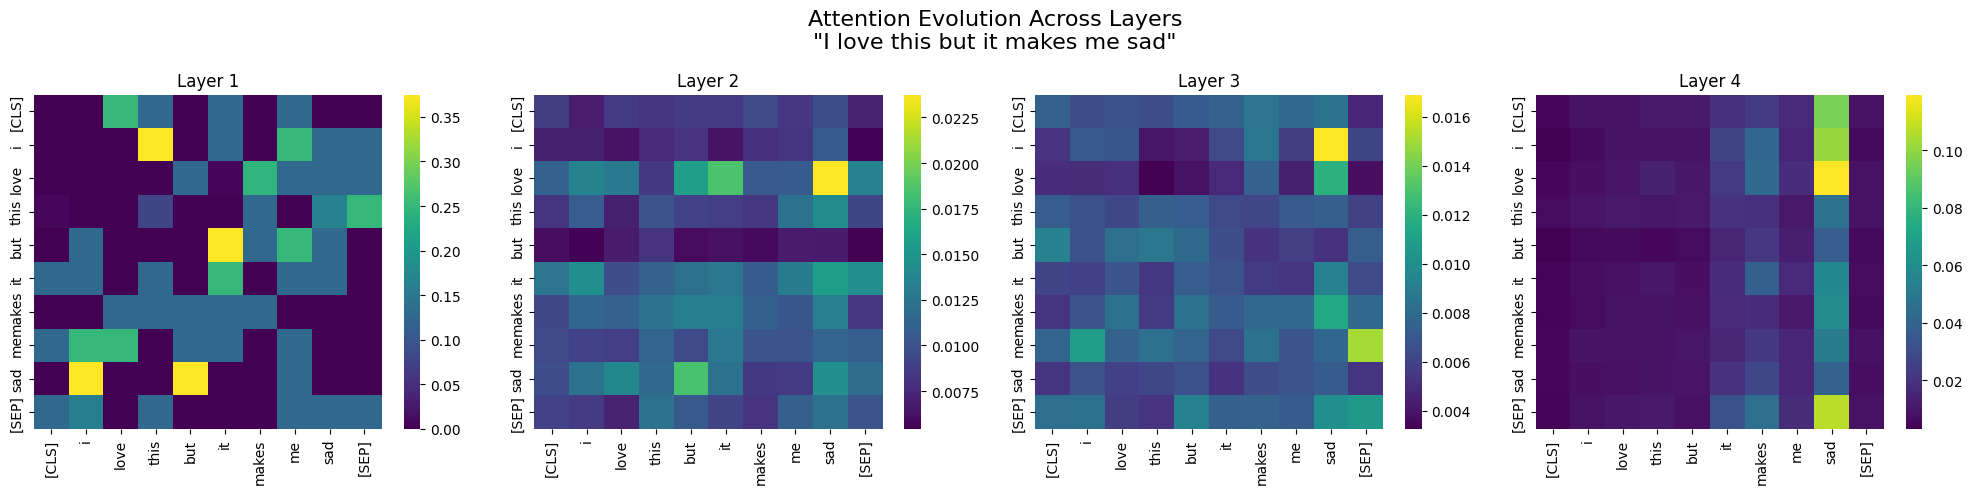

In [32]:
def analyze_layers(model, text, tokenizer, device):
    """Show how attention evolves through layers"""
    model.eval()

    inputs = tokenizer(text, return_tensors='pt', padding='max_length',
                      truncation=True, max_length=128).to(device)

    with torch.no_grad():
        outputs, attention_weights = model(inputs['input_ids'])

    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    actual_length = (inputs['input_ids'][0] != tokenizer.pad_token_id).sum().item()
    tokens = tokens[:actual_length]

    num_layers = len(attention_weights)
    fig, axes = plt.subplots(1, num_layers, figsize=(5*num_layers, 5))

    for layer_idx in range(num_layers):
        # Average across all heads
        avg_attention = attention_weights[layer_idx][0].mean(0)[:actual_length, :actual_length].cpu().numpy()

        sns.heatmap(avg_attention, ax=axes[layer_idx], cmap='viridis',
                   xticklabels=tokens, yticklabels=tokens, cbar=True)
        axes[layer_idx].set_title(f'Layer {layer_idx + 1}')
        axes[layer_idx].set_xlabel('')
        axes[layer_idx].set_ylabel('')

    plt.suptitle(f'Attention Evolution Across Layers\n"{text}"', fontsize=16)
    plt.tight_layout()
    plt.show()

analyze_layers(model, "I love this but it makes me sad", tokenizer, device)